# Deep Learning – Rendu 1 : CNN sur EuroSAT  

## Rendu le 21/12

**Auteur :** *BESSADET Theo* — **UE :** Deep Learning — **Deadline envisagée :** 13 décembre
**Données :** EuroSAT (torchvision) — occupation des sols en imagerie satellite, 10 classes, images 64×64×3.

## Consignes

- **Baseline** : un CNN dont l'architecture est 100 % maîtrisée (comme dans les premiers TP).
- **Réseaux pré-entraînés** : au moins un modèle classique (type ImageNet), idéalement deux pour comparer. Le transfert doit être fait par moi-même.
- **Stratégies d'apprentissage** : comparer au moins deux techniques, modèle complètement gelé vs fine-tuning (total ou partiel).
- **Taille de l'échantillon d'apprentissage** *(optionnel)* : comparer les performances selon la taille du jeu d'entraînement, jusqu'à 1 % des données.
- **Probing / sondage** : ajouter des hooks et brancher des sondes pour savoir où est encodée quelle information.
- **Analyses** : des zones de texte pour commenter les résultats.
- **Interprétabilité** : montrer quelque chose sur la décision, avec de la saillance ou du CAM.
- **Option** : comparer avec des modèles pré-entraînés sur les données cibles (HuggingFace).
- **Évaluation** : notebook + discussion rapide en séance de TP.

## Plan

1. **Données et préparation** : chargement d'EuroSAT, split train/val/test, normalisation, visualisation de quelques exemples.
2. **CNN fait maison (baseline)** : architecture codée par mes soins, entraînement, courbes, résultats.
3. **CNN construit avec les modules PyTorch** : *(même architecture réécrite avec `nn.Module` / `nn.Sequential`)*, entraînement et comparaison avec la baseline.
4. Comparaison des deux modèles
5. **Fine-tuning d'un modèle CNN pré-entraîné** : *ResNet18 et *
   - modèle gelé (extraction de caractéristiques) ;
   - fine-tuning partiel ;
   - fine-tuning complet.
6. **L-TAE** (article vu récemment) : *essayer de l'appliquer par rapport au projet ?*
7. **Comparaison selon la taille du jeu d'entraînement** *(optionnel)* : 1 %, 10 %, 100 %.
8. **Probing** : hooks sur les couches intermédiaires et sondes.
9. **Interprétabilité** : saillance ou Grad-CAM.
10. **Conclusion** : tableau récapitulatif et discussion.


## 1. Données et préparation

- **Chargement** : `torchvision.datasets.EuroSAT` (27 000 images RGB 64×64, 10 classes), téléchargé dans `data/`. Les images sont converties en tenseurs `(N, 3, 64, 64)` dans [0, 1] puis toutes chargées sur le GPU (≈ 1,3 Go en float32) pour éviter les allers-retours CPU/GPU.
- **Split stratifié** (classes légèrement déséquilibrées, 2 000 à 3 000 images par classe) : 20 % test, puis 10 % du reste en validation → ≈ 19 400 / 2 200 / 5 400 images. Le **test est mis de côté** jusqu'à l'évaluation finale ; la validation sert à l'early stopping.
- **Normalisation par canal** : moyenne et écart-type calculés **sur le train uniquement** (pas de fuite vers val/test), puis appliqués aux trois jeux.

In [1]:
%load_ext autoreload
%autoreload 2

import copy
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from CNN import Conv, Dense, DropOut, Flatten, Modele, Pool, ReLu
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.models import ResNet, ResNet18_Weights, resnet18
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import inspect
from pathlib import Path

import mlflow

mlflow.set_tracking_uri("sqlite:///" + Path("mlflow.db").resolve().as_posix())
mlflow.set_experiment("EuroSAT_CNN")
print("device :", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device : cuda | NVIDIA GeForce RTX 5070 Ti


In [2]:
# Chargement : images PIL -> tenseurs (3, 64, 64) dans [0, 1]
eurosat = datasets.EuroSAT(root="data", download=True, transform=transforms.PILToTensor())   # uint8, (3, 64, 64)
classes = eurosat.classes

y = torch.tensor(eurosat.targets, dtype=torch.long)

loader = DataLoader(eurosat, batch_size=512, shuffle=False, num_workers=max(1, os.cpu_count() // 2))  # shuffle=False : ordre = celui de y
X = torch.cat([xb for xb, _ in tqdm(loader, desc="Chargement")])    # (27000, 3, 64, 64) uint8

# Split stratifié sur les indices : test 20 %, puis validation 10 % du reste
idx = np.arange(len(y))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42, stratify=y.numpy())
idx_train, idx_val = train_test_split(idx_train, test_size=0.1, random_state=42, stratify=y[idx_train].numpy())

# Tout sur le device : uint8 -> float32 dans [0, 1], puis normalisation par canal (stats du train uniquement)
X = X.to(device).float().div_(255.)
y = y.to(device)
idx_train, idx_val, idx_test = (torch.tensor(i, device=device) for i in (idx_train, idx_val, idx_test))

mean = X[idx_train].mean(dim=(0, 2, 3), keepdim=True)   # (1, 3, 1, 1)
std = X[idx_train].std(dim=(0, 2, 3), keepdim=True)
X.sub_(mean).div_(std)                                  # en place : évite une copie de 1,3 Go

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]
del X

print("X_train :", X_train.shape, "\nX_val :", X_val.shape, "\nX_test :", X_test.shape)
print("Classes :", classes)

Chargement:   0%|          | 0/53 [00:24<?, ?it/s]

X_train : torch.Size([19440, 3, 64, 64]) 
X_val : torch.Size([2160, 3, 64, 64]) 
X_test : torch.Size([5400, 3, 64, 64])
Classes : ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


torch.Size([3, 64, 64]) torch.Size([1, 1, 1, 3, 64, 64])
AnnualCrop


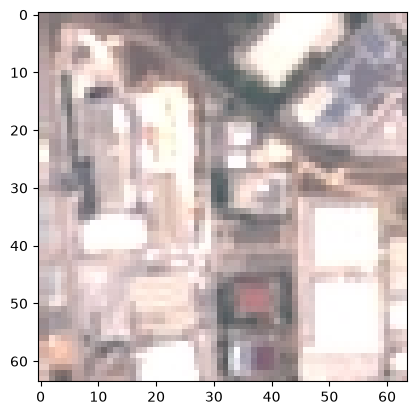

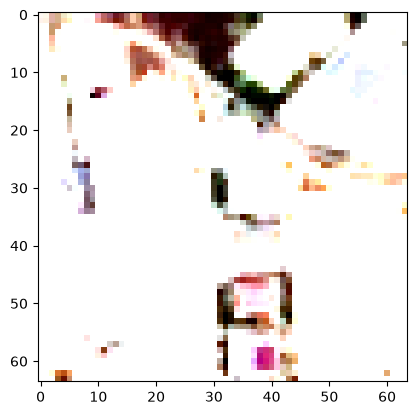

In [3]:
X1 = X_train[0,:,:,:]
X1_brute = X1 * std[:, None, None] + mean[:, None, None]

print(X1.shape, X1_brute.shape)

print(classes[y[0].cpu()])
plt.imshow(X1_brute.cpu().squeeze(0,1,2).permute(1, 2, 0))
plt.figure()
plt.imshow(X1.cpu().permute(1, 2, 0).clamp(0, 1))

## 2. CNN fait maison (baseline)

Les couches et la classe `Modele` sont importées depuis `CNN.py` (repris de `CNN.ipynb`).

**Architecture** (inspirée du modèle "large" de MNIST, adaptée à des images 64×64×3) : 3 blocs `Conv 3×3 (same) → ReLu → MaxPool 2×2`, avec un nombre de filtres doublé à chaque pooling (32 → 64 → 128), puis `DropOut(0.3) → Flatten → Dense(128) → ReLu → Dense(10)`.

| Étape | Sortie |
|---|---|
| Entrée | 3 × 64 × 64 |
| Bloc 1 (32 filtres) | 32 × 32 × 32 |
| Bloc 2 (64 filtres) | 64 × 16 × 16 |
| Bloc 3 (128 filtres) | 128 × 8 × 8 |
| Flatten → Dense → Dense | 8 192 → 128 → 10 |

- **Padding `same`** : la taille n'est réduite que par le pooling, ce qui garde une carte 8×8 en sortie des features (utile plus tard pour le Grad-CAM).
- **3 blocs** plutôt que 2 : les images sont plus grandes et plus riches (textures, couleurs) que MNIST.
- **≈ 1,14 M paramètres**, dont ≈ 92 % dans la première Dense : c'est la principale source de sur-apprentissage, d'où le DropOut juste avant.

**Hyperparamètres** : SGD simple (pas de momentum, comme dans `Modele`), `lr = 0.05` (plus faible que sur MNIST car le réseau est plus profond et sans BatchNorm), `batch_size = 128`, 60 epochs maximum, early stopping sur la loss de validation avec `patience = 8`. Ces valeurs sont un point de départ, à ajuster sur la validation (jamais sur le test).

In [4]:
def probas(model, x):
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model.forward(x[i:i + model.batch_size]) for i in range(0, len(x), model.batch_size)])
    return torch.softmax(logits.double(), dim=1).cpu().numpy()   # double : sklearn vérifie que chaque ligne somme à 1

def probas_torch(model, x, batch_size=128):
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model(x[i:i + batch_size]) for i in range(0, len(x), batch_size)])
    return torch.softmax(logits.double(), dim=1).cpu().numpy()

def stats_par_classe(proba, y_true):
    '''DataFrame : une ligne par classe + une ligne "moyenne" ; colonnes : loss, accuracy, F1, ROC AUC, average precision'''
    pred = proba.argmax(axis=1)
    y_bin = np.eye(len(classes))[y_true]          # (N, n_classes) : one-hot, pour les métriques "une classe contre les autres"
    lignes = []
    for k in range(len(classes)):
        masque = y_true == k
        lignes.append({
            "loss":              -np.log(np.clip(proba[masque, k], 1e-12, None)).mean(),   # -log(proba de la vraie classe), images de la classe k
            "accuracy":          (pred[masque] == k).mean(),                               # = rappel de la classe k
            "F1":                f1_score(y_bin[:, k], pred == k),
            "ROC AUC":           roc_auc_score(y_bin[:, k], proba[:, k]),
            "average precision": average_precision_score(y_bin[:, k], proba[:, k]),
        })
    df = pd.DataFrame(lignes, index=classes)
    df.loc["moyenne (macro)"] = df.mean()
    return df

def log_confusion_probas(proba, y_true):
    '''Dans le run MLflow actif : matrice de confusion (image) et stats par classe (table) en artefacts'''
    pred = proba.argmax(axis=1)
    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title("Matrice de confusion (validation)")
    fig.tight_layout()
    mlflow.log_figure(fig, "matrice_confusion_val.png")
    plt.close(fig)       # évite l'affichage de la figure dans la cellule
    df = stats_par_classe(proba, y_true).round(4).rename_axis("classe").reset_index()
    mlflow.log_table(df, "stats_par_classe_val.json")


In [5]:
def creer_modele_v2(input_shape=(3, 64, 64), EPOCH=60, lr=0.1, batch_size=128, patience=10, eps=1e-4, **kwargs):
    mp, r = Pool(2, 2, 'max'), ReLu()     # sans état : réutilisables
    features = [Conv(3, 32, 3, padding='same'), r, mp,                                          # (B, 32, 32, 32)
                Conv(32, 64, 3, padding='same'), r, Conv(64, 64, 3, padding='same'), r, mp,     # (B, 64, 16, 16)
                Conv(64, 128, 3, padding='same'), r, Conv(128, 128, 3, padding='same'), r, mp,  # (B, 128, 8, 8)
                Conv(128, 256, 3, padding='same'), r, mp,                                       # (B, 256, 4, 4)
                DropOut(p=0.3)]
    classifier = [Flatten(), Dense(n_out=128), r, DropOut(p=0.3), Dense(n_out=10)]              # 4096 -> 128 -> 10
    return Modele(features, classifier, input_shape=input_shape, EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=patience, eps=eps, **kwargs)

def fit_maison(model, x, y, x_val, y_val, **_):      # **_ : ignore les hyperparamètres (déjà dans le modèle)
    model.fit(x, y, x_val, y_val)
    for epoch, (tl, ta, vl, va) in enumerate(model.perf_fit):    # fit maison ne loggue pas par epoch
        mlflow.log_metrics({"train_loss": float(tl), "train_acc": float(ta),
                            "val_loss": float(vl), "val_acc": float(va)}, step=epoch)
    return model.perf_fit

def evaluer_maison(model, x, y):
    return model.evaluate(x, y)                      # (loss, accuracy)

In [ ]:
def creer_modele_torch_v2():
    r, mp = nn.ReLU(), nn.MaxPool2d(2, 2)
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding='same'), r, mp,                                                # (B, 32, 32, 32)
        nn.Conv2d(32, 64, 3, padding='same'), r, nn.Conv2d(64, 64, 3, padding='same'), r, mp,      # (B, 64, 16, 16)
        nn.Conv2d(64, 128, 3, padding='same'), r, nn.Conv2d(128, 128, 3, padding='same'), r, mp,   # (B, 128, 8, 8)
        nn.Conv2d(128, 256, 3, padding='same'), r, mp,                                             # (B, 256, 4, 4)
        nn.Dropout(0.3),
        nn.Flatten(), nn.Linear(256 * 4 * 4, 128), r, nn.Dropout(0.3), nn.Linear(128, 10),         # 4096 -> 128 -> 10
    ).to(device)

def augmenter_torch(x):
    '''Parmi les 8 symétries du carré (4 rotations de 90° x retournement), tirée au hasard pour chaque image. x : (N, C, H, W) avec H = W'''
    N = x.shape[0]
    k = torch.randint(0, 4, (N,), device=x.device)
    x = torch.stack([torch.rot90(x, j, dims=(2, 3)) for j in range(4)])    # (4, N, C, H, W)
    x = x[k, torch.arange(N, device=x.device)]                              # (N, C, H, W)
    flip = torch.rand(N, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def evaluer_torch(model, x, y, batch_size=128):
    model.eval()
    critere = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct = 0., 0
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            yhat = model(x[i:i+batch_size])
            total_loss += critere(yhat, y[i:i+batch_size]).item()
            correct += (yhat.argmax(dim=1) == y[i:i+batch_size]).sum().item()
    return total_loss / len(x), correct / len(x)   # loss, accuracy

def predire_torch(model, x, batch_size=128):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i+batch_size]).argmax(dim=1) for i in range(0, len(x), batch_size)])

def fit_torch(model, x, y, x_val, y_val, EPOCH=60, lr=0.05, batch_size=128, patience=8, eps=1e-4,
              momentum=0.0, lr_decay=1.0, augment=False, freeze="aucun"):
    optimiseur = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimiseur, gamma=lr_decay)   # lr de l'epoch e = lr * lr_decay**e
    critere = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=True, drop_last=True)
    perf_fit, min_loss, best_state, wait = [], float("inf"), None, 0

    barre_epoch = tqdm(range(EPOCH), desc="Epochs")
    for epoch in barre_epoch:
        model.train()

        if freeze == 'rn18':
            for module in model.modules():               # Faire en sorte que les moyennes mobiles ne bougent pas
                    if isinstance(module, nn.BatchNorm2d):
                        module.eval()

        batch_loss, batch_accuracy = [], []
        for xb, yb in tqdm(loader, desc="Batchs", leave=False):
            if augment:
                xb = augmenter_torch(xb)
            yhat = model(xb)
            loss = critere(yhat, yb)
            optimiseur.zero_grad()
            loss.backward()
            optimiseur.step()
            batch_loss.append(loss.item())
            batch_accuracy.append((yhat.argmax(dim=1) == yb).float().mean().item())
        scheduler.step()    # fin d'epoch : mise à jour du lr

        val_loss, val_accuracy = evaluer_torch(model, x_val, y_val, batch_size)

        perf_fit.append([np.mean(batch_loss), np.mean(batch_accuracy), val_loss, val_accuracy])
        if mlflow.active_run():
            mlflow.log_metrics({"train_loss": round(float(np.mean(batch_loss)), 4), "train_acc": round(float(np.mean(batch_accuracy)), 4),
                                "val_loss": round(float(val_loss), 4), "val_acc": round(float(val_accuracy), 4)}, step=epoch)

        barre_epoch.set_postfix(loss=f"{np.mean(batch_loss):.4f}", val_loss=f"{val_loss:.4f}", val_acc=f"{val_accuracy:.4f}")

        if val_loss < min_loss - eps:
            wait, min_loss = 0, val_loss
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                tqdm.write(f"Early stop at epoch {epoch + 1}")
                break

    model.load_state_dict(best_state)
    model.eval()
    print(f"Stop apres {len(perf_fit)} epochs : val_loss={min_loss:.4f}")
    return perf_fit

def mlflow_load(model, name, strategie="", fit=fit_torch, evaluer=evaluer_torch, probabilites=probas_torch, archi=None, **params):
    print(f"=== {name} ===")
    impl = "maison" if isinstance(model, Modele) else "pytorch"
    torch.manual_seed(42)
    n_params = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Paramètres : {n_params:,} (entraînables : {n_train:,})")

    defauts_torch = {k: v.default for k, v in inspect.signature(fit).parameters.items()
                 if v.default is not inspect.Parameter.empty}
    hyper = {**defauts_torch, **params}

    with mlflow.start_run(run_name=f"{impl} {name}"):
        # --- Contexte : paramètres, hyperparamètres, tags
        mlflow.log_params({**hyper, "modele": name, "implementation": impl, "seed": 42,
                           "n_params": n_params, "n_params_entrainables": n_train,
                           "n_train": len(X_train), "n_val": len(X_val)})
        mlflow.set_tags({"strategie": strategie, "device": str(device),
                         "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})

        # --- Code : cellule appelante, architecture, fonction d'entraînement
        mlflow.log_text(_ih[-1], "cellule_modeles_torch.py")
        mlflow.log_text(archi if archi is not None else str(model), "architecture.py")
        mlflow.log_text(inspect.getsource(fit), "fit_torch.py")

        # --- Entraînement
        t0 = time.time()
        perf_fit = fit(model, X_train, y_train, X_val, y_val, **params)
        temps = time.time() - t0

        # --- Métriques sur la validation (modèle = meilleurs poids restaurés)
        y_np = y_val.cpu().numpy()
        proba = probabilites(model, X_val)
        pred = proba.argmax(axis=1)
        val_loss, val_acc = evaluer(model, X_val, y_val)

        perf = np.array(perf_fit)                  # colonnes : train_loss, train_acc, val_loss, val_acc
        best = int(perf[:, 2].argmin())

        mlflow.log_metrics({
            "best_val_loss": round(val_loss, 4),
            "val_OA": round(val_acc, 4),                                         # overall accuracy
            "val_f1_macro": round(f1_score(y_np, pred, average="macro"), 4),
            "train_loss_at_best": round(perf[best, 0], 4),
            "train_acc_at_best": round(perf[best, 1], 4),
            "gap_acc_train_val": round(perf[best, 1] - perf[best, 3], 4),       # écart de sur-apprentissage
            "best_epoch": best + 1,
            "epochs": len(perf_fit),
            "early_stopped": int(len(perf_fit) < hyper["EPOCH"]),
            "temps_min": round(temps / 60, 2),
            "temps_par_epoch_s": round(temps / len(perf_fit), 2),
        })

        # --- Artefacts : matrice de confusion et stats par classe
        log_confusion_probas(proba, y_np)
    
    return perf_fit, temps


In [ ]:
configs = {
    "base":             (creer_modele_v2, {}),
    "augmentation":     (creer_modele_v2, {'augment': True}),
    "momentum + decay": (creer_modele_v2, {"lr": 0.02, "momentum": 0.9, "lr_decay": 0.95}),
    "tout":             (creer_modele_v2, {"lr": 0.02, "momentum": 0.9, "lr_decay": 0.95, "augment": True}),
}

modeles_v2, perfs_v2, temps_v2 = {}, {}, {}
defauts = {k: v.default for k, v in inspect.signature(creer_modele_v2).parameters.items()
           if v.default is not inspect.Parameter.empty}

for nom, (creer, params) in configs.items():
    torch.manual_seed(42)
    modeles_v2[nom] = creer(**params)
    perfs_v2[nom], temps_v2[nom] = mlflow_load(modeles_v2[nom], nom, strategie='maison',
                                               fit=fit_maison, evaluer=evaluer_maison, probabilites=probas,
                                               archi=inspect.getsource(creer_modele_v2), 
                                               **{**defauts, **params})

## 3. CNN construit avec les modules PyTorch

**Même architecture** que la baseline, réécrite avec `nn.Sequential` : `nn.Conv2d(padding='same')`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Dropout`, `nn.Flatten`, `nn.Linear`. La boucle d'entraînement utilise `torch.optim.SGD` et `nn.CrossEntropyLoss` (log-softmax + NLL, comme dans `Modele`).

**Mêmes hyperparamètres** (SGD sans momentum, `lr = 0.05`, `batch_size = 128`, 60 epochs max, `patience = 8` sur la loss de validation, restauration des meilleurs poids) pour que la comparaison porte sur l'implémentation et non sur les réglages.

Seule différence volontairement conservée : l'**initialisation par défaut de PyTorch** (Kaiming uniforme) au lieu de `randn / √(fan_in)`. On pourrait aussi passer à Adam ou ajouter du momentum, mais la comparaison ne serait plus équitable.

In [ ]:
configs_torch = {
    "v2":      (creer_modele_torch_v2, {"lr": 0.1, "patience": 10}),
    "v2 tout": (creer_modele_torch_v2, {"lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": True}),
}

modeles_t, perfs_t, temps_t = {}, {}, {}
for nom, (creer, params) in configs_torch.items():
    torch.manual_seed(42)
    modeles_t[nom] = creer()
    perfs_t[nom], temps_t[nom] = mlflow_load(modeles_t[nom], nom, strategie='full training', **params)
    print(f"{int(temps_t[nom])} secondes")

## 4. Comparaison des deux implémentations

Les deux modèles étant **figés** (aucun choix ne sera fait à partir de ces chiffres), on peut les évaluer sur le **jeu de test** : c'est l'évaluation finale.

- **Métriques** : loss (cross-entropy), accuracy et **F1 macro** (moyenne non pondérée des F1 par classe, adaptée au léger déséquilibre des classes).
- **Coût** : nombre de paramètres, nombre d'epochs avant l'early stopping et temps d'entraînement (la version PyTorch utilise les convolutions optimisées cuDNN, la version maison passe par `unfold` + `einsum`).
- **Graphique** : courbes de loss train / validation des deux modèles, pour comparer la vitesse de convergence et le sur-apprentissage.

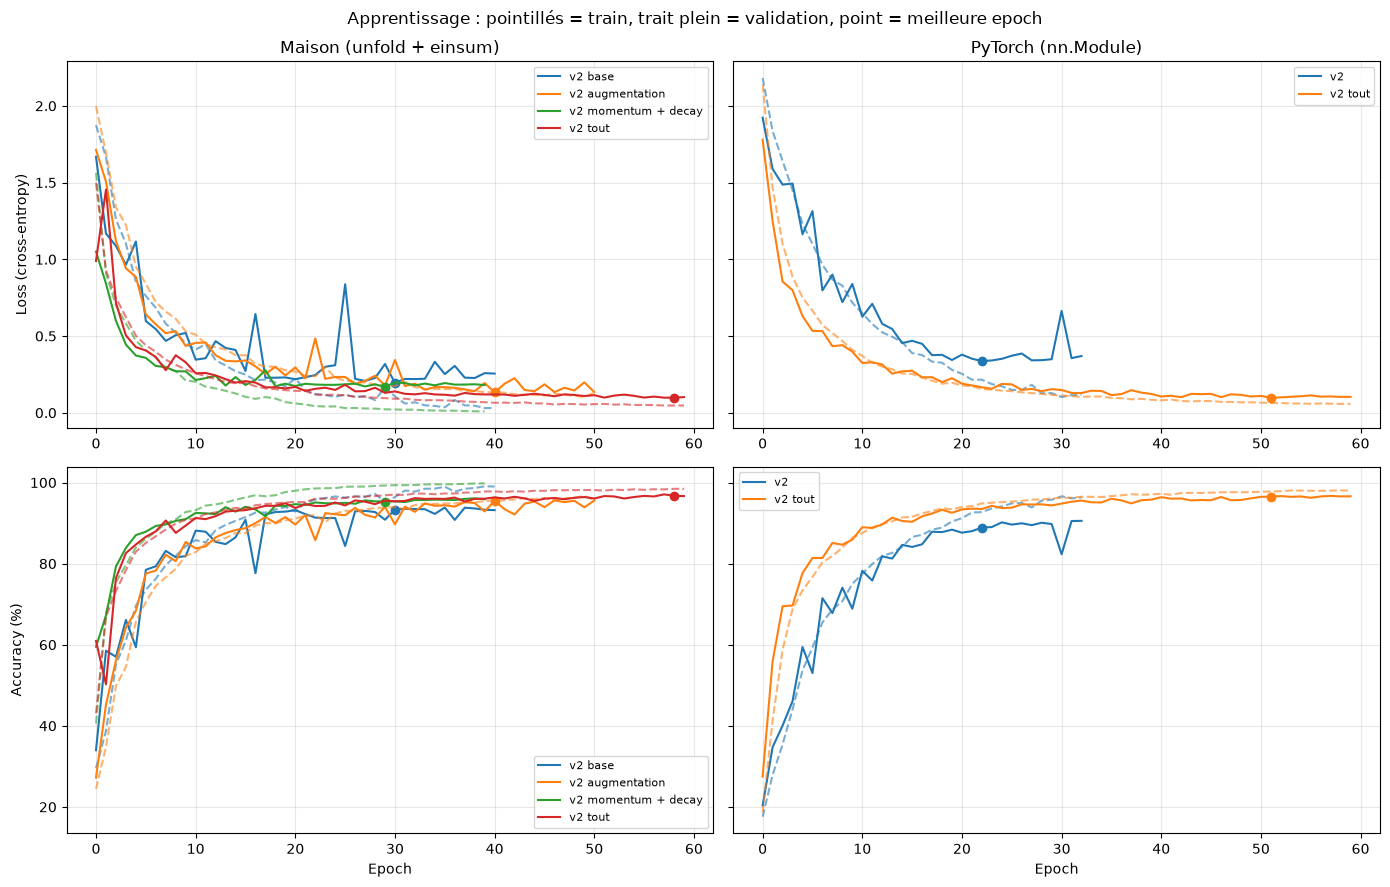

In [9]:
# Vue d'ensemble : lignes = loss / accuracy, colonnes = implémentation maison / PyTorch
# Pointillés = train, trait plein = validation, point = meilleure epoch (poids conservés par l'early stopping)
groupes = {
    "Maison (unfold + einsum)": {**{f"v2 {nom}": m.perf_fit for nom, m in modeles_v2.items() if getattr(m, "perf_fit", None)}},
    "PyTorch (nn.Module)":      perfs_t,
}

fig, axes = plt.subplots(2, len(groupes), figsize=(7 * len(groupes), 9), sharey="row", squeeze=False)
for j, (titre, runs) in enumerate(groupes.items()):
    for i, (nom, perf_fit) in enumerate(runs.items()):
        perf = np.array(perf_fit)           # colonnes : train_loss, train_acc, val_loss, val_acc
        best = perf[:, 2].argmin()
        couleur = f"C{i}"
        axes[0, j].plot(perf[:, 0], color=couleur, linestyle="--", alpha=0.6)
        axes[0, j].plot(perf[:, 2], color=couleur, label=nom)
        axes[0, j].plot(best, perf[best, 2], "o", color=couleur)
        axes[1, j].plot(perf[:, 1] * 100, color=couleur, linestyle="--", alpha=0.6)
        axes[1, j].plot(perf[:, 3] * 100, color=couleur, label=nom)
        axes[1, j].plot(best, perf[best, 3] * 100, "o", color=couleur)
    axes[0, j].set_title(titre)
    axes[1, j].set_xlabel("Epoch")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
axes[0, 0].set_ylabel("Loss (cross-entropy)")
axes[1, 0].set_ylabel("Accuracy (%)")
fig.suptitle("Apprentissage : pointillés = train, trait plein = validation, point = meilleure epoch")
plt.tight_layout()
plt.savefig("data/resume_partie3_maison_vs_pytorch.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Meilleur modèle parmi ceux des deux groupes (maison + PyTorch), choisi sur la validation
y_np = y_val.cpu().numpy()
candidats = {
    **{f"maison {nom}": probas(m, X_val) for nom, m in modeles_v2.items()},
    **{f"torch {nom}":  probas_torch(m, X_val) for nom, m in modeles_t.items()},
}
losses = {nom: -np.log(np.clip(p[np.arange(len(y_np)), y_np], 1e-12, None)).mean() for nom, p in candidats.items()}

best_model = min(losses, key=losses.get)    # plus petite loss de validation
print("Classement des modèdes :")
for nom, l in sorted(losses.items(), key=lambda kv: kv[1]):
    print(f"{nom:<25} val_loss={l:.4f}  acc={(candidats[nom].argmax(axis=1) == y_np).mean() * 100:.2f} %")
print(f"\nMeilleur modèle : {best_model}\n")

proba = candidats[best_model]
pred = proba.argmax(axis=1)

print(f"F1 macro          : {f1_score(y_np, pred, average='macro'):.4f}")
print(f"ROC AUC (ovr)     : {roc_auc_score(y_np, proba, multi_class='ovr'):.4f}")
print(f"average precision : {average_precision_score(np.eye(len(classes))[y_np], proba, average='macro'):.4f}")
display(stats_par_classe(proba, y_np).round(4))

Classement des modèdes :
torch v2 tout             val_loss=0.0980  acc=96.53 %
maison tout               val_loss=0.0980  acc=96.76 %
maison augmentation       val_loss=0.1326  acc=95.51 %
maison momentum + decay   val_loss=0.1684  acc=95.32 %
maison base               val_loss=0.1946  acc=93.33 %
torch v2                  val_loss=0.3371  acc=88.89 %

Meilleur modèle : torch v2 tout

F1 macro          : 0.9644
ROC AUC (ovr)     : 0.9992
average precision : 0.9932


,loss,accuracy,F1,ROC AUC,average precision
AnnualCrop,0.0832,0.9833,0.9692,0.9991,0.9939
Forest,0.0507,0.9875,0.9875,0.9999,0.9993
HerbaceousVegetation,0.1444,0.9333,0.9392,0.9985,0.9851
Highway,0.0808,0.9650,0.9626,0.9994,0.9942
Industrial,0.0628,0.9800,0.9776,0.9998,0.9978
Pasture,0.1483,0.9562,0.9653,0.9990,0.9917
PermanentCrop,0.1716,0.9250,0.9158,0.9978,0.9804
Residential,0.0542,0.9833,0.9854,0.9999,0.9995
River,0.1850,0.9400,0.9543,0.9986,0.9903
SeaLake,0.0339,0.9875,0.9875,0.9999,0.9994


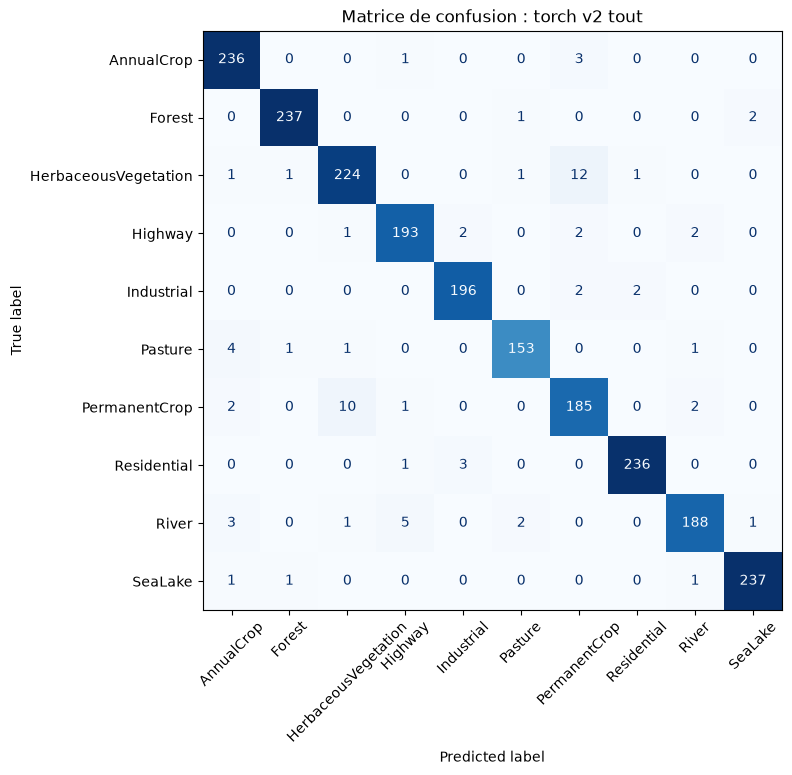

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(y_np, pred), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title(f"Matrice de confusion : {best_model}")
plt.tight_layout()
plt.savefig("data/matrice_confusion_best_model.png", dpi=150, bbox_inches="tight")
plt.show()

### TODO ###
## 5. FineTuning
Quel modèle ? Tester un CNN et un transformer style L-TAE ?

Cahier de bord :  
Import du modele resnet
Il faut le passer sur GPU pour accelerer les calculs
le forward de base produit sortie (N, 1000) $\to$ remplace la derniere couche du linéaire (actuellement n $\to$ 1000) par du n $\to$ 10  
**Structure de ResNet18 (simplifiée) :**
- Entrée : 
  - Conv2d (N,3,64,64) $\to$ (N,64,32,32) 
  - BatchNorm2D : Pour le batch actuel, dans chaque canal, `BatchNorm` fait une normalisation centrée réduite des valeurs. En evaluation, on utilise pas $\mu$|$\sigma$ du batch, mais la moyennes mobiles de $\mu$ et $\sigma²$. L'objectif est de garder des activations stables d'une couche à l'autre (converge + vite et accepte lr plus grand), evite explosion/vanishing gradient
  - ReLU : activation non linéaire classique
  - MaxPool2D(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False) : (N,64,32,32) $\to$ (N, 64, 16, 16)
- Layer : 4 suite de 2 block, contenant [conv1, bn1, relu, conv2, bn2]. Avec downsample dans 2, 3 et 4 car l'entrée et la sortie de taille différente, alors qu'on a une connexion résiduelle.
  - Layer 1 : (N, 64, 16, 16) $\to$ (N, 64, 16, 16)
  - Layer 2 : (N, 64, 16, 16) $\to$ (N, 128, 8, 8)
  - Layer 3 : (N, 128, 8, 8) $\to$ (N, 256, 4, 4)
  - Layer 4 : (N, 256, 4, 4) $\to$ (N, 512, 2, 2)
-` AdaptiveAvgPool2d((1, 1))` : On fixe la taille de la sortie, et ca accepte n'importe quel taille d'entrée (permet de faire passer image en entrée taille 64x64, 128x128 ... ) : (N, 512, 2, 2) $\to$ (N, 512, 1, 1)
- fc (full_connected) : couche dense de sortie. Actuellement `fc = Linear(512, 1000)` (adapter aux 1000 classes ImageNet) $\to$ a changer pour 10 sortie

In [ ]:
rn18 = resnet18(weights = ResNet18_Weights.DEFAULT).to(device)

for p in rn18.parameters(): 
    p.requires_grad = False
rn18.fc = nn.Linear(in_features=512, out_features=10, bias=True).to(device)

params = {'EPOCH': 60, 'lr': 0.005, 'batch_size': 128, 'patience': 8, 'eps': 1e-4, 'momentum': 0.9, 'lr_decay': 1, 'augment': False, 'freeze': 'rn18'}
perf, t = mlflow_load(rn18, 'ResNet18 gelé', strategie='gelé', **params)
print(f"{t} secondes")